# Part 2, Sanath: Laplace and heteroscedastic Gaussian linear models

**Models.** (1) a linear model with an *absolute-loss* (Laplace likelihood) objective, (2) a linear model whose *variance also depends on the inputs* (heteroscedastic Gaussian).
**Features.** log-transformed inputs and station climatology, organised in named groups (`cache/features_C.py`).
**Lectures used.** L7, L11 to L13 (probabilistic view of regression: likelihood, MLE, noise models).

Basically, PM2.5 is strongly right-skewed and changes *multiplicatively* (a clean day goes from 20 to 30, a smoggy day from 200 to 300). So we have modelled `log1p(PM2.5)`. In log space the noise is much closer to symmetric, and the choice of noise model decides what the model optimises: **Laplace noise gives least absolute deviations (median regression), which is exactly the MAE-optimal forecast**, and because the median commutes with `log`, `expm1(prediction)` is the exact conditional median in ug/m3. For RMSE we need the conditional *mean* instead, which we recover with a small, training-only correction factor (smearing). The heteroscedastic Gaussian adds an uncertainty estimate, and uses it for the same mean correction.

## 0. Setup
A quick copy-paste setup.

In [ ]:
import os, sys, random, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED)
np.random.seed(SEED)

REPO_URL = "https://github.com/ponishbhatia/manifold-CS771.git"
ROOT = Path.cwd()
if not (ROOT / "baseline.py").exists() and (ROOT.parent / "baseline.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "baseline.py").exists():
    subprocess.run(["git", "clone", REPO_URL, "manifold-CS771"], check=True)
    ROOT = Path.cwd() / "manifold-CS771"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import baseline as B
B.self_check()

baseline.py OK


,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81


## 1. Data and split (shared rules)
Train = targets 3 Jan to 31 Aug, validation = targets 1 Sep to 30 Nov. Everything that is *fitted* (scalers, climatology, smearing factor, model weights) uses training rows only.

In [ ]:
W, stations = B.load_data()
T_train, T_val = B.issue_times()
y_train, y_val = B.targets(W, T_train), B.targets(W, T_val)

assert len(y_train) == 113_256 and len(y_val) == 42_588
assert T_train.max() + pd.Timedelta(hours=24) <= pd.Timestamp("2024-08-31 12:00")
assert T_val.min() + pd.Timedelta(hours=24) >= pd.Timestamp("2024-09-01 12:00")
assert not np.isnan(y_train).any() and not np.isnan(y_val).any()
print(W.shape, "| train rows", len(y_train), "| val rows", len(y_val))

(8040, 468) | train rows 113256 | val rows 42588


## 2. Why work in log space?
Three facts from the training data motivate everything that follows: the target is very right-skewed, readings are capped at 500 by the sensor, and the level changes by a factor of 10 or more across seasons (so a *multiplicative* model is natural).

skewness  raw: 2.38   log1p: 0.33
share of readings at the 500 cap: 0.003%


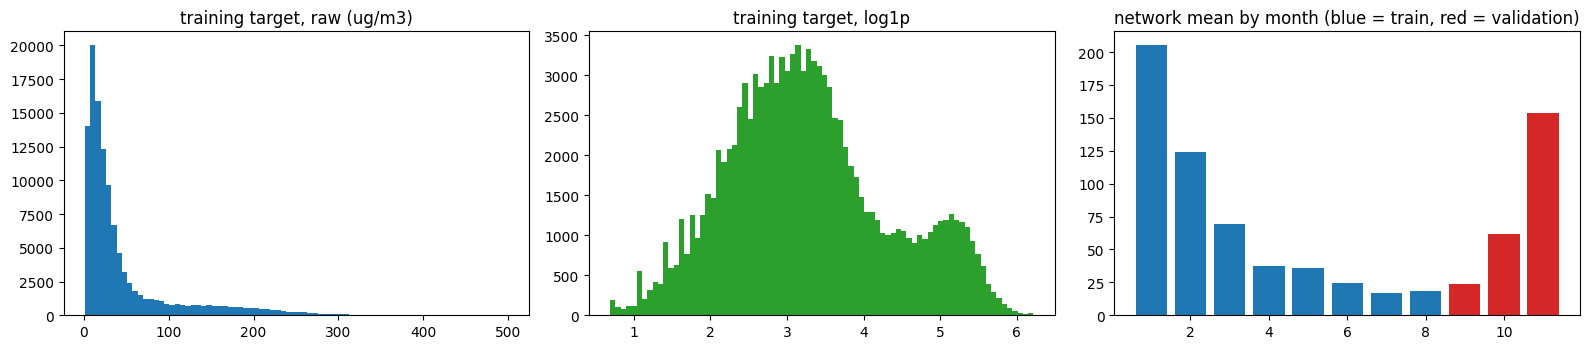

In [ ]:
log_train = np.log1p(y_train)
log_val = np.log1p(y_val)
print(f"skewness  raw: {pd.Series(y_train).skew():.2f}   log1p: {pd.Series(log_train).skew():.2f}")
print(f"share of readings at the 500 cap: {np.mean(W.to_numpy() >= 499.5):.3%}")

monthly_mean = W.mean(axis=1).groupby(W.index.month).mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].hist(y_train, bins=80, color="tab:blue")
axes[0].set_title("training target, raw (ug/m3)")
axes[1].hist(log_train, bins=80, color="tab:green")
axes[1].set_title("training target, log1p")
colors = ["tab:blue" if month <= 8 else "tab:red" for month in monthly_mean.index]
axes[2].bar(monthly_mean.index, monthly_mean.values, color=colors)
axes[2].set_title("network mean by month (blue = train, red = validation)")
plt.tight_layout()
plt.show()

Note the right panel: training sees a *falling* season (Jan winter down to the July trough) and validation is a *rising* season (Sep up to the Nov winter peak). This distribution shift is the main difficulty in this project, and it is why November error dominates every model.

## 3. Features (`cache/features_C.py`)
Every feature is a function of `(history, issue time)` and only uses readings at or before the issue time `t`. All pollution inputs are `log1p`-transformed. Groups:

| group | idea | columns |
|---|---|---|
| `own` | log readings at lags 0,1,2,3,6,12,18,23 h plus mean/min/max/std of the last 24 h of log readings | 12 |
| `prevday` | log reading at t - 24 h | 1 |
| `nbr` | log means over the 10 and 75 nearest stations (now and 24 h mean), and the station's local anomaly versus its 10 neighbours | 5 |
| `network` | log network mean now, its 24 h log change, spread across stations | 3 |
| `trend` | log-ratio momentum: 18 h change, last 6 h vs previous 6 h, last 24 h vs previous 24 h | 3 |
| `long` | log 7-day station mean | 1 |

Tried and *not* kept (shown in the ablation): `clim` (station climatology = training-period mean, plus anomalies versus it), `long30` (30-day mean), `calendar` (sin/cos of day of year).

The tests below are the ones from `suggestions.md`: shape, no NaN, no leakage, and parity between the batch matrix and a single-issue-time call (so the same code can be used in `forecast.py`).

In [ ]:
from cache import features_C as F

ctx = F.build_ctx(W, stations)
X_train, feature_names, group_columns = F.extract_features(W, T_train, ctx, F.FINAL_GROUPS)
X_val, _, _ = F.extract_features(W, T_val, ctx, F.FINAL_GROUPS)

assert X_train.shape == (113_256, len(feature_names)) and X_val.shape == (42_588, len(feature_names))
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

for time_list, X_batch, position in [(T_val, X_val, 10), (T_train, X_train, 0), (T_train, X_train, 100)]:
    t = time_list[position]
    from_full_history, _, _ = F.extract_features(W, [t], ctx, F.FINAL_GROUPS)
    from_cut_history, _, _ = F.extract_features(W.loc[:t], [t], ctx, F.FINAL_GROUPS)
    assert np.allclose(from_full_history, from_cut_history), "leakage"
    assert np.allclose(from_full_history, X_batch[position * 468:(position + 1) * 468]), "parity"
print("shape, NaN, leakage and parity tests passed")
for group, columns in group_columns.items():
    print(f"{group:8s} ({len(columns):2d}):", [feature_names[c] for c in columns])

shape, NaN, leakage and parity tests passed
own      (12): ['log_lag0', 'log_lag1', 'log_lag2', 'log_lag3', 'log_lag6', 'log_lag12', 'log_lag18', 'log_lag23', 'log_mean24', 'log_min24', 'log_max24', 'log_std24']
prevday  ( 1): ['log_d1']
nbr      ( 5): ['log_nbr10_now', 'log_nbr10_mean24', 'log_nbr75_now', 'log_nbr75_mean24', 'local_anom']
network  ( 3): ['log_net_now', 'log_net_chg24', 'net_log_std']
trend    ( 3): ['log_chg18', 'log_mom6', 'log_chg_day']
long     ( 1): ['log_mean7d']


## 4. Model 1: Laplace (absolute-loss) linear model

**Likelihood view.** Suppose `z = log1p(y) = w.x + b + noise`.
- Gaussian noise: the negative log-likelihood is proportional to the sum of squared errors, so MLE = ordinary least squares, and the best forecast is the *mean*.
- Laplace noise, density proportional to `exp(-|e| / s)`: the negative log-likelihood is proportional to the sum of **absolute** errors, so MLE = least absolute deviations, and the best forecast is the *median*.

**How to fit it.** Absolute value is not differentiable at 0, so we use *iteratively reweighted least squares* (IRLS). Because `|r| = r^2 / |r|`, one step of weighted least squares with weights `1 / |r|` (using the previous residuals) decreases the absolute loss. Repeat until the loss stops changing (about 20 iterations here).

**Check that my implementation is right** against scikit-learn's exact linear-programming solver on a subsample (they should reach the same loss):

In [ ]:
from cache.probmodels_C import LaplaceLinear, HeteroscedasticGaussian, LogLaplaceForecaster, LogHeteroGaussianForecaster
from sklearn.linear_model import QuantileRegressor, LinearRegression

rng = np.random.default_rng(SEED)
subsample = rng.choice(len(y_train), 3000, replace=False)
standardised = (X_train[subsample] - X_train[subsample].mean(axis=0)) / X_train[subsample].std(axis=0)

mine = LaplaceLinear(l2=0.0).fit(X_train[subsample], log_train[subsample])
reference = QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs").fit(standardised, log_train[subsample])
mean_absolute_error = lambda predicted: np.mean(np.abs(log_train[subsample] - predicted))
print(f"mean |error|   mine (IRLS): {mean_absolute_error(mine.predict(X_train[subsample])):.5f}   scikit-learn LP: {mean_absolute_error(reference.predict(standardised)):.5f}")

mean |error|   mine (IRLS): 0.36529   scikit-learn LP: 0.36528


### 4a. Which target space? (level vs log, squared vs absolute loss)
Same 28 features, four different recipes. Everything is converted back to ug/m3 and scored with `B.evaluate`.

In [ ]:
def summarise(name, forecast):
    scores = B.evaluate(forecast, y_val, T_val)
    return dict(model=name, RMSE=scores["RMSE"], MAE=scores["MAE"], RMSE_Nov=scores["RMSE Nov"],
                bias=np.mean(np.clip(forecast, 0, None) - y_val))

laplace = LogLaplaceForecaster().fit(X_train, y_train)
rows = [
    summarise("OLS, level target", LinearRegression().fit(X_train, y_train).predict(X_val)),
    summarise("Laplace (LAD), level target", LaplaceLinear().fit(X_train, y_train).predict(X_val)),
    summarise("OLS, log1p target, expm1", np.expm1(LinearRegression().fit(X_train, log_train).predict(X_val))),
    summarise("Laplace, log1p target, median", laplace.predict(X_val, mode="median")),
    summarise("Laplace, log1p target, smeared mean", laplace.predict(X_val, mode="mean")),
]
pd.DataFrame(rows).round(2)

,model,RMSE,MAE,RMSE_Nov,bias
0,"OLS, level target",34.70,22.96,49.33,6.18
1,"Laplace (LAD), level target",37.18,21.32,57.35,-4.58
2,"OLS, log1p target, expm1",30.68,16.76,45.96,-8.29
3,"Laplace, log1p target, median",29.27,16.02,43.28,-6.00
4,"Laplace, log1p target, smeared mean",28.16,15.74,41.05,-0.30


**Reading this table.**
1. Level targets are bad: the model has to hit values from 5 to 500 with one additive formula. Log space fixes that.
2. Within log space, Laplace (absolute loss) beats OLS (squared loss): the heavy tails of the log residuals make squared loss chase outliers.
3. *Median vs mean.* The median forecast has the best MAE (it is exactly the MAE-optimal forecast), but it **under-predicts on average** (negative bias) because PM2.5 is right-skewed: mean > median. RMSE rewards the mean, so we multiply `exp(mu)` by the *smearing factor* `mean(exp(training residual))` (Duan, 1983), computed on training rows only. The exact formula for Laplace noise would be `E[exp(z)] = exp(mu) / (1 - s^2)`; the empirical factor is the safer choice because the real residuals are not exactly Laplace (see the numbers below: they have lighter tails than Laplace, closer to Gaussian).

Laplace scale s = 0.371
if residuals were exactly Laplace: 1/(1-s^2) = 1.159
if residuals were Gaussian with the same mean |error|: 1.114
empirical smearing factor (training residuals): 1.119


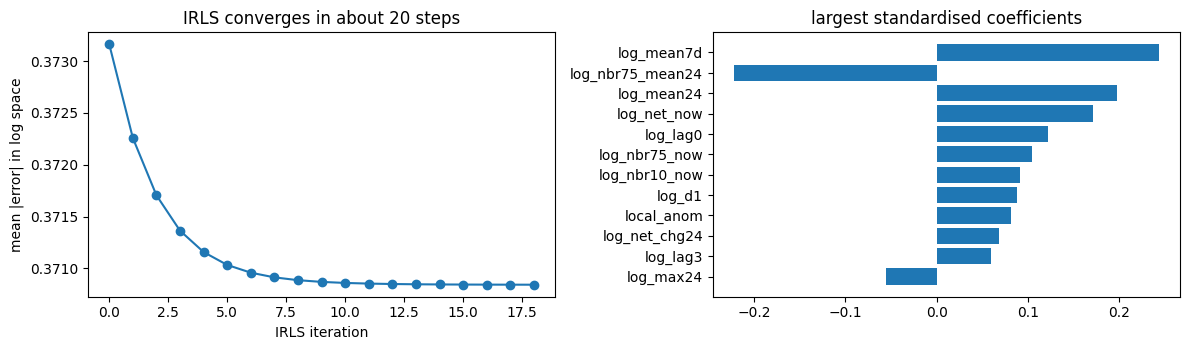

In [ ]:
scale_s = laplace.model_.scale_b_
print(f"Laplace scale s = {scale_s:.3f}")
gaussian_equivalent = np.exp((scale_s * np.sqrt(np.pi / 2)) ** 2 / 2)
print(f"if residuals were exactly Laplace: 1/(1-s^2) = {1 / (1 - scale_s ** 2):.3f}")
print(f"if residuals were Gaussian with the same mean |error|: {gaussian_equivalent:.3f}")
print(f"empirical smearing factor (training residuals): {laplace.smearing_:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(laplace.model_.loss_history_, marker="o")
axes[0].set_xlabel("IRLS iteration")
axes[0].set_ylabel("mean |error| in log space")
axes[0].set_title("IRLS converges in about 20 steps")
coefficients = pd.Series(laplace.model_.coef_[1:], index=feature_names).sort_values(key=np.abs, ascending=False).head(12)
axes[1].barh(coefficients.index[::-1], coefficients.values[::-1])
axes[1].set_title("largest standardised coefficients")
plt.tight_layout()
plt.show()

## 5. Model 2: heteroscedastic Gaussian linear model
Now both the mean *and the variance* are linear functions of the inputs (variance through a log link so it stays positive):

`log1p(y) ~ Normal(mu(x), sigma^2(x))`, with `mu = w.x + b` and `log sigma^2 = v.x + c`.

Training maximises the likelihood with L-BFGS using exact gradients (derived in `cache/probmodels_C.py`). Intuition: a day the model knows is unpredictable gets a large `sigma`, so its squared error counts less when fitting `w` (a learned weighted least squares).

The mean forecast in ug/m3 is the *log-normal mean* `exp(mu + sigma^2/2) - 1`, so the learned variance directly drives the back-transformation correction.

**Is the uncertainty honest?** Check (a) calibration of central prediction intervals on validation, (b) validation negative log-likelihood against a constant-variance Gaussian, (c) predicted vs actual spread per month.

In [ ]:
from scipy.stats import norm

hetero = LogHeteroGaussianForecaster().fit(X_train, y_train)
mu_train, _ = hetero.predict_log_distribution(X_train)
mu_val, sigma_val = hetero.predict_log_distribution(X_val)
months_val = np.repeat((T_val + pd.Timedelta(hours=24)).month, 468)

print("optimiser converged:", hetero.model_.result_.success, "| iterations:", hetero.model_.result_.nit)
coverage = {f"{int(level * 100)}%": round(float(np.mean(np.abs(log_val - mu_val) <= norm.ppf(0.5 + level / 2) * sigma_val)), 3) for level in (0.5, 0.8, 0.9)}
print("central interval coverage on validation (nominal -> actual):", coverage)

negative_log_likelihood = lambda mu, sigma: np.mean(0.5 * np.log(2 * np.pi * sigma ** 2) + 0.5 * ((log_val - mu) / sigma) ** 2)
constant_sigma = np.sqrt(np.mean((log_train - mu_train) ** 2))
print(f"validation NLL (log space): heteroscedastic {negative_log_likelihood(mu_val, sigma_val):.3f}   constant sigma {negative_log_likelihood(mu_val, constant_sigma):.3f}")

spread = pd.DataFrame({
    "mean predicted sigma": [sigma_val[months_val == month].mean() for month in (9, 10, 11)],
    "actual residual std": [np.std((log_val - mu_val)[months_val == month]) for month in (9, 10, 11)],
    "mean residual": [np.mean((log_val - mu_val)[months_val == month]) for month in (9, 10, 11)],
}, index=["Sep", "Oct", "Nov"])
spread.round(3)

optimiser converged: True | iterations: 247
central interval coverage on validation (nominal -> actual): {'50%': 0.548, '80%': 0.838, '90%': 0.917}
validation NLL (log space): heteroscedastic 0.629   constant sigma 0.683


,mean predicted sigma,actual residual std,mean residual
Sep,0.512,0.525,-0.020
Oct,0.439,0.457,0.032
Nov,0.457,0.435,0.110


The intervals are close to calibrated (nominal 80% gives about 84%), the heteroscedastic likelihood is clearly better than a constant-variance Gaussian, and the predicted spread follows the real monthly spread. Note the positive mean residual in November: the model still slightly under-predicts the rising winter season, which is the distribution-shift problem again.

## 6. Ablation: what does each feature group add?
Final model = Laplace on `log1p`, smeared-mean forecast. For each group: refit **without** it (same hyper-parameters) and record the change in validation RMSE/MAE. Positive delta = the group helped. Below that, groups that were *not* in the final model are added one at a time.

In [ ]:
ALL_GROUPS = list(F.GROUPS)
X_train_all, all_names, all_columns = F.extract_features(W, T_train, ctx, ALL_GROUPS)
X_val_all, _, _ = F.extract_features(W, T_val, ctx, ALL_GROUPS)
columns_of = lambda groups: [column for group in groups for column in all_columns[group]]

def fit_and_score(groups):
    columns = columns_of(groups)
    model = LogLaplaceForecaster().fit(X_train_all[:, columns], y_train)
    scores = B.evaluate(model.predict(X_val_all[:, columns]), y_val, T_val)
    return dict(n_features=len(columns), RMSE=scores["RMSE"], MAE=scores["MAE"], RMSE_Sep=scores["RMSE Sep"],
                RMSE_Oct=scores["RMSE Oct"], RMSE_Nov=scores["RMSE Nov"])

full_scores = fit_and_score(F.FINAL_GROUPS)
ablation = [dict(setting="final model (6 groups)", **full_scores, delta_RMSE=0.0, delta_MAE=0.0)]
for group in F.FINAL_GROUPS:
    scores = fit_and_score([other for other in F.FINAL_GROUPS if other != group])
    ablation.append(dict(setting=f"- {group}", **scores, delta_RMSE=scores["RMSE"] - full_scores["RMSE"], delta_MAE=scores["MAE"] - full_scores["MAE"]))
for group in ["clim", "long30", "calendar"]:
    scores = fit_and_score(F.FINAL_GROUPS + [group])
    ablation.append(dict(setting=f"+ {group}", **scores, delta_RMSE=scores["RMSE"] - full_scores["RMSE"], delta_MAE=scores["MAE"] - full_scores["MAE"]))
first_draft = fit_and_score(["own", "prevday", "clim", "nbr", "network", "trend"])
ablation.append(dict(setting="first draft (with clim, no long)", **first_draft,
                     delta_RMSE=first_draft["RMSE"] - full_scores["RMSE"], delta_MAE=first_draft["MAE"] - full_scores["MAE"]))
ablation_table = pd.DataFrame(ablation).set_index("setting")
display(ablation_table.round(2))

additive_rows = []
for extra in [None, "prevday", "nbr", "network", "trend", "long"]:
    groups = ["own"] if extra is None else ["own", extra]
    additive_rows.append(dict(setting="own alone" if extra is None else f"own + {extra}", **fit_and_score(groups)))
additive_table = pd.DataFrame(additive_rows).set_index("setting")
additive_table["RMSE_gain_vs_own"] = additive_table.loc["own alone", "RMSE"] - additive_table["RMSE"]
additive_table["MAE_gain_vs_own"] = additive_table.loc["own alone", "MAE"] - additive_table["MAE"]
display(additive_table.round(2))

,n_features,RMSE,MAE,RMSE_Sep,RMSE_Oct,RMSE_Nov,delta_RMSE,delta_MAE
setting,,,,,,,,
final model (6 groups),25,28.16,15.74,20.05,17.57,41.05,0.00,0.00
- own,13,28.24,15.77,19.84,17.50,41.34,0.08,0.03
- prevday,24,28.16,15.74,20.15,17.56,41.00,0.00,-0.01
- nbr,20,28.42,15.96,20.24,17.97,41.31,0.25,0.22
- network,22,28.98,16.18,20.08,17.95,42.56,0.82,0.44
- trend,22,28.15,15.74,20.06,17.58,41.02,-0.01,-0.01
- long,24,28.37,16.18,20.23,18.18,41.11,0.21,0.44
+ clim,29,28.28,15.77,20.47,17.71,41.02,0.12,0.03
+ long30,26,28.47,15.62,20.13,17.10,41.86,0.31,-0.12


,n_features,RMSE,MAE,RMSE_Sep,RMSE_Oct,RMSE_Nov,RMSE_gain_vs_own,MAE_gain_vs_own
setting,,,,,,,,
own alone,12,29.93,17.20,20.51,19.30,43.73,0.00,0.00
own + prevday,13,29.91,17.19,20.39,19.27,43.75,0.02,0.01
own + nbr,17,29.43,16.74,20.46,18.50,43.07,0.50,0.46
own + network,15,28.87,16.60,20.67,18.76,41.67,1.06,0.60
own + trend,15,29.79,17.14,20.41,19.25,43.49,0.14,0.06
own + long,13,29.45,16.58,20.23,18.58,43.18,0.48,0.62


**Caution about small differences.** The validation set is 91 days that are strongly correlated with each other, so differences of 0.1 to 0.3 RMSE are within noise. To avoid fooling ourselves with a validation-set search, the next cell re-checks the key feature choices with **rolling-origin validation inside the training period only** (train on early months, test on the following months), which never touches the validation set. (`clim` is skipped there because its training mean would leak the test months.)

In [ ]:
target_times_train = (T_train + pd.Timedelta(hours=24)).repeat(468)
folds = {
    "train <= Mar, test Apr-May": ("2024-03-31 23:59", "2024-04-01", "2024-05-31 23:59"),
    "train <= May, test Jun-Jul": ("2024-05-31 23:59", "2024-06-01", "2024-07-31 23:59"),
    "train <= Jun, test Jul-Aug": ("2024-06-30 23:59", "2024-07-01", "2024-08-31 23:59"),
}
candidates = {
    "final (6 groups)": F.FINAL_GROUPS,
    "final - long": [g for g in F.FINAL_GROUPS if g != "long"],
    "final + long30": F.FINAL_GROUPS + ["long30"],
    "final + calendar": F.FINAL_GROUPS + ["calendar"],
}
lag0_column = all_names.index("log_lag0")
rolling_rows = []
for fold_name, (train_end, test_start, test_end) in folds.items():
    in_train = target_times_train <= pd.Timestamp(train_end)
    in_test = (target_times_train >= pd.Timestamp(test_start)) & (target_times_train <= pd.Timestamp(test_end))
    persistence_forecast = np.expm1(X_train_all[in_test, lag0_column])
    rolling_rows.append(dict(fold=fold_name, model="persistence",
                             RMSE=np.sqrt(np.mean((persistence_forecast - y_train[in_test]) ** 2)),
                             MAE=np.mean(np.abs(persistence_forecast - y_train[in_test]))))
    for name, groups in candidates.items():
        columns = columns_of(groups)
        model = LogLaplaceForecaster().fit(X_train_all[in_train][:, columns], y_train[in_train])
        forecast = model.predict(X_train_all[in_test][:, columns])
        rolling_rows.append(dict(fold=fold_name, model=name,
                                 RMSE=np.sqrt(np.mean((forecast - y_train[in_test]) ** 2)),
                                 MAE=np.mean(np.abs(forecast - y_train[in_test]))))
rolling = pd.DataFrame(rolling_rows)
for metric in ("RMSE", "MAE"):
    print(metric)
    display(rolling.pivot(index="model", columns="fold", values=metric)[list(folds)].round(2))

RMSE


fold,"train <= Mar, test Apr-May","train <= May, test Jun-Jul","train <= Jun, test Jul-Aug"
model,,,
final (6 groups),19.12,17.05,17.45
final + calendar,18.95,16.95,18.08
final + long30,19.19,17.06,17.48
final - long,19.28,16.85,17.40
persistence,23.15,20.37,21.25


MAE


fold,"train <= Mar, test Apr-May","train <= May, test Jun-Jul","train <= Jun, test Jul-Aug"
model,,,
final (6 groups),8.47,7.81,7.61
final + calendar,8.66,8.54,9.53
final + long30,8.43,7.78,7.56
final - long,9.07,7.83,7.75
persistence,9.87,8.76,8.88


## 7. Final comparison against the baselines
`B.compare` puts persistence and the Part 1 ridge on top. Train RMSE is computed with the same forecasts on the training rows (to see the generalisation gap).

In [ ]:
final_predictions = {
    "C: Laplace median (MAE-optimal)": laplace.predict(X_val, mode="median"),
    "C: Laplace smeared mean (FINAL)": laplace.predict(X_val, mode="mean"),
    "C: Heteroscedastic Gaussian": hetero.predict(X_val),
}
train_predictions = {
    "C: Laplace median (MAE-optimal)": laplace.predict(X_train, mode="median"),
    "C: Laplace smeared mean (FINAL)": laplace.predict(X_train, mode="mean"),
    "C: Heteroscedastic Gaussian": hetero.predict(X_train),
}
comparison = B.compare(final_predictions, W, stations, T_val)
comparison["Train RMSE"] = [np.nan, np.nan] + [round(float(np.sqrt(np.mean((train_predictions[name] - y_train) ** 2))), 2) for name in final_predictions]
comparison

,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov,Train RMSE
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70,NaN
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81,NaN
C: Laplace median (MAE-optimal),29.27,16.02,20.22,7.49,17.49,10.62,43.28,30.13,28.05
C: Laplace smeared mean (FINAL),28.16,15.74,20.05,7.88,17.57,10.95,41.05,28.56,28.01
C: Heteroscedastic Gaussian,28.69,16.05,20.00,8.00,17.38,10.84,42.24,29.50,27.68


**Is the improvement real?** A paired *block bootstrap* over validation days (7-day blocks, because consecutive days are correlated): the 95% interval for `RMSE(final) - RMSE(other)`. If the whole interval is below 0, the final model is better.

In [ ]:
def daily_squared_error(forecast):
    return ((np.clip(forecast, 0, None) - y_val) ** 2).reshape(len(T_val), 468).mean(axis=1)

def block_bootstrap_interval(squared_error_a, squared_error_b, block=7, n_boot=2000, seed=SEED):
    generator = np.random.default_rng(seed)
    n_days = len(squared_error_a)
    n_blocks = int(np.ceil(n_days / block))
    differences = []
    for _ in range(n_boot):
        starts = generator.integers(0, n_days - block + 1, n_blocks)
        indices = np.concatenate([np.arange(start, start + block) for start in starts])[:n_days]
        differences.append(np.sqrt(squared_error_a[indices].mean()) - np.sqrt(squared_error_b[indices].mean()))
    return np.percentile(differences, [2.5, 50, 97.5]).round(2)

final_squared_error = daily_squared_error(final_predictions["C: Laplace smeared mean (FINAL)"])
others = {"Persistence": B.persistence(W, T_val), "Ridge (Part 1)": B.part1_ridge_predict(W, stations, T_val)}
others["C: Laplace median"] = final_predictions["C: Laplace median (MAE-optimal)"]
others["C: Heteroscedastic Gaussian"] = final_predictions["C: Heteroscedastic Gaussian"]
print("delta RMSE = RMSE(final) - RMSE(other), 95% block-bootstrap interval [2.5%, 50%, 97.5%]")
for name, forecast in others.items():
    print(f"  vs {name:28s}", block_bootstrap_interval(final_squared_error, daily_squared_error(forecast)))

delta RMSE = RMSE(final) - RMSE(other), 95% block-bootstrap interval [2.5%, 50%, 97.5%]
  vs Persistence                  [-5.56 -3.84 -2.37]
  vs Ridge (Part 1)               [-1.9  -0.83 -0.27]


  vs C: Laplace median            [-2.51 -1.35 -0.23]
  vs C: Heteroscedastic Gaussian  [-1.28 -0.62  0.01]


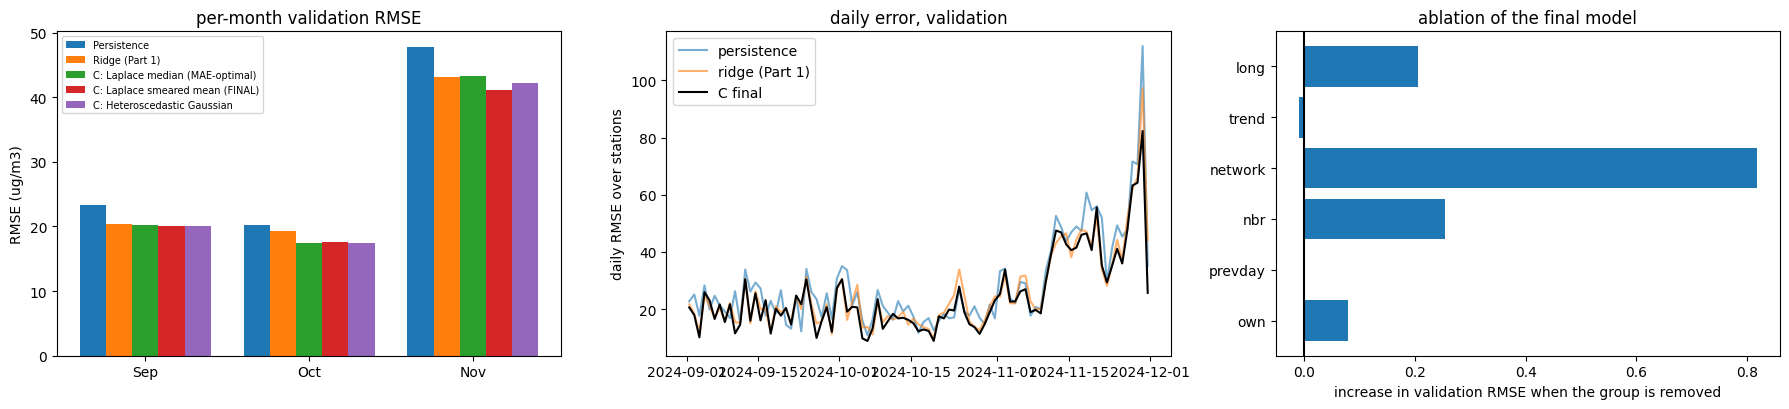

In [ ]:
dates = T_val + pd.Timedelta(hours=24)
persistence_error = np.sqrt(daily_squared_error(B.persistence(W, T_val)))
ridge_error = np.sqrt(daily_squared_error(others["Ridge (Part 1)"]))
final_error = np.sqrt(final_squared_error)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
months = ["RMSE Sep", "RMSE Oct", "RMSE Nov"]
plotted = ["Persistence", "Ridge (Part 1)", "C: Laplace median (MAE-optimal)", "C: Laplace smeared mean (FINAL)", "C: Heteroscedastic Gaussian"]
for position, name in enumerate(plotted):
    axes[0].bar(np.arange(3) + 0.16 * position, comparison.loc[name, months].values, 0.16, label=name)
axes[0].set_xticks(np.arange(3) + 0.32)
axes[0].set_xticklabels(["Sep", "Oct", "Nov"])
axes[0].set_ylabel("RMSE (ug/m3)")
axes[0].set_title("per-month validation RMSE")
axes[0].legend(fontsize=7)

axes[1].plot(dates, persistence_error, alpha=0.6, label="persistence")
axes[1].plot(dates, ridge_error, alpha=0.6, label="ridge (Part 1)")
axes[1].plot(dates, final_error, color="k", label="C final")
axes[1].set_ylabel("daily RMSE over stations")
axes[1].set_title("daily error, validation")
axes[1].legend()

drops = ablation_table.loc[[f"- {group}" for group in F.FINAL_GROUPS], "delta_RMSE"]
axes[2].barh([name[2:] for name in drops.index], drops.values)
axes[2].axvline(0, color="k")
axes[2].set_xlabel("increase in validation RMSE when the group is removed")
axes[2].set_title("ablation of the final model")
plt.tight_layout()
plt.savefig("models/fig_C_summary.png", dpi=150)
plt.show()

## 8. Save validation predictions and the results log
`preds/<name>_<model>.parquet`: 91 target days x 468 stations, in ug/m3, plus a CSV with the columns of the shared results sheet.

In [ ]:
Path("preds").mkdir(exist_ok=True)
target_times = T_val + pd.Timedelta(hours=24)

def save_predictions(file_name, forecast):
    frame = pd.DataFrame(np.clip(forecast, 0, None).reshape(len(T_val), 468), index=target_times, columns=stations.index)
    frame.to_parquet(f"preds/{file_name}.parquet")
    check = pd.read_parquet(f"preds/{file_name}.parquet")
    assert check.shape == (91, 468) and not check.isna().any().any() and (check.values >= 0).all()
    return check.shape

print(save_predictions("sanath_laplace_mean", final_predictions["C: Laplace smeared mean (FINAL)"]))
print(save_predictions("sanath_laplace_median", final_predictions["C: Laplace median (MAE-optimal)"]))
print(save_predictions("sanath_hetgauss", final_predictions["C: Heteroscedastic Gaussian"]))

log_rows = []
descriptions = {
    "C: Laplace median (MAE-optimal)": ("Laplace linear (IRLS), median forecast", "l2=1e-3"),
    "C: Laplace smeared mean (FINAL)": ("Laplace linear (IRLS), smeared-mean forecast", "l2=1e-3, smearing=%.3f" % laplace.smearing_),
    "C: Heteroscedastic Gaussian": ("Heteroscedastic Gaussian linear, log-normal mean", "l2=1e-3"),
}
for name, (model_name, hyperparameters) in descriptions.items():
    scores = comparison.loc[name]
    log_rows.append(dict(Member="C", Model=model_name, Features="+".join(F.FINAL_GROUPS), Target="log1p(PM2.5)",
                         Hyperparameters=hyperparameters, Train_RMSE=scores["Train RMSE"], Val_RMSE=scores["RMSE"],
                         Val_MAE=scores["MAE"], Sep=scores["RMSE Sep"], Oct=scores["RMSE Oct"], Nov=scores["RMSE Nov"],
                         Notes="no clim/calendar; see ablation"))
pd.DataFrame(log_rows).to_csv("results_log_C.csv", index=False)
pd.DataFrame(log_rows).round(2)

(91, 468)
(91, 468)


(91, 468)


,Member,Model,Features,Target,Hyperparameters,Train_RMSE,Val_RMSE,Val_MAE,Sep,Oct,Nov,Notes
0,C,"Laplace linear (IRLS), median forecast",own+prevday+nbr+network+trend+long,log1p(PM2.5),l2=1e-3,28.05,29.27,16.02,20.22,17.49,43.28,no clim/calendar; see ablation
1,C,"Laplace linear (IRLS), smeared-mean forecast",own+prevday+nbr+network+trend+long,log1p(PM2.5),"l2=1e-3, smearing=1.119",28.01,28.16,15.74,20.05,17.57,41.05,no clim/calendar; see ablation
2,C,"Heteroscedastic Gaussian linear, log-normal mean",own+prevday+nbr+network+trend+long,log1p(PM2.5),l2=1e-3,27.68,28.69,16.05,20.00,17.38,42.24,no clim/calendar; see ablation


## 9. Report answers and discussion

**Headline.** Laplace linear model on `log1p(PM2.5)` with the smeared-mean back-transformation: validation **RMSE 28.16, MAE 15.74** (persistence 32.75 / 17.47, Ridge Part 1 29.58 / 18.16). It beats both baselines in every month on both metrics (Sep 20.05 / 7.88, Oct 17.57 / 10.95, Nov 41.05 / 28.56). Train RMSE is 28.01 against 28.16 on validation, so there is no overfitting.

### Question 1: What did each feature group add? Which ideas did not help, and why?
Two views are needed because groups overlap (for example `local_anom = log(lag0) - log(neighbour mean)`, so `nbr` contains `lag0` information too). *Drop-one* (section 6, first table) measures only the **unique** contribution; *add-on-top-of-`own`* (second table) measures the **total** contribution.

| group | drop-one: RMSE / MAE worse by | added to `own`: RMSE / MAE better by | comment |
|---|---|---|---|
| `network` | +0.82 / +0.44 | +1.06 / +0.60 | the biggest gain by far; a state-wide level and 24 h change tells the model whether the whole region is moving up or down, which no single station history can say. This matters most when the season turns (Nov). |
| `nbr` | +0.25 / +0.22 | +0.50 / +0.46 | neighbour means de-noise a single sensor, and `local_anom` separates local from regional pollution. |
| `long` (7-day mean) | +0.21 / +0.44 | +0.48 / +0.62 | a slowly varying "background level" for the station; helps MAE most, RMSE slightly. |
| `own` | +0.08 / +0.03 | (baseline: 29.93 / 17.20 alone) | looks useless in drop-one only because the other groups reproduce `lag0`; on its own it is a decent model. |
| `trend` | -0.01 / -0.01 | +0.14 / +0.06 | essentially redundant with `own` (differences of log lags). |
| `prevday` | 0.00 / -0.01 | +0.02 / +0.01 | adds nothing: yesterday's noon reading is already inside the 24 h summaries. |

Ideas that **did not help** (and why I think so):
- **Station climatology `clim`** (the C-model feature the assignment table suggests): +0.12 RMSE worse. The training mean of a station is mostly its Jan to Aug seasonal average (winter smog plus monsoon trough), not a stable station identity, and the station's recent readings and neighbours already carry the spatial pattern. It is a constant per station, so it cannot tell the model anything about *tomorrow*.
- **`long30` (30-day mean)**: RMSE +0.31 worse on validation, MAE 0.12 better, and neutral in all three rolling-origin folds, so no consistent gain. A 30-day window in September and October still reaches back into the August trough, so it lags behind the rising season.
- **`calendar` (sin/cos of day of year)**: clearly harmful on validation (+1.79 RMSE, +2.48 MAE) and it worsens MAE in all three rolling folds. Training only contains days 3 to 244 of the year, and validation (days 245 to 335) is outside that range, so the model has to extrapolate a seasonal curve it learned from a *falling* season into a *rising* one.
- **Level (non-log) target**: much worse (see 4a). **Squared loss in log space** (OLS) is worse than absolute loss: 30.68 / 16.76 vs 29.27 / 16.02 for the median forecast.

**How the final set was chosen (honesty note).** I looked at the validation ablation, so some selection is involved, but (i) the differences between feature sets are 0.1 to 0.35 RMSE while the gain over Ridge is 1.4, (ii) my *first-draft* set (with `clim`, without `long`) already scored 28.51 / 16.18 and beats both baselines, and (iii) the rolling-origin check inside the training period (which never touches validation) supports dropping `calendar` and treating `clim`/`long30` as neutral.

### Question 2: Did a better model beat Ridge on validation? Train vs validation?
Yes. Versus Ridge (Part 1): RMSE 28.16 vs 29.58 (-1.42, about 5%), MAE 15.74 vs 18.16 (-2.42, about 13%), better in every month on both metrics. A paired 7-day-block bootstrap puts the 95% interval for the RMSE difference at [-1.90, -0.27], which excludes zero (the point estimate is -1.42; the bootstrap median is smaller because a few extreme November days dominate the squared error). Versus persistence the interval is [-5.56, -2.37].

This model is not "more flexible" than Ridge (it is also linear), so the gain does not come from capacity. It comes from three modelling choices: (1) the log transform, which removes the skew and makes effects multiplicative; (2) the absolute-loss (Laplace) likelihood, which is robust to the huge spikes and is the right loss for MAE; (3) the smearing correction, which turns the median back into a mean when RMSE is the metric. Ridge's weak MAE (worse than persistence, 18.16 vs 17.47) is the symptom of fitting squared error on a skewed target.

The model does not overfit (train 28.01, validation 28.16). The remaining error is **distribution shift**, not variance: November RMSE is 41.05 against 17 to 20 in the earlier months, and the log-space residual in November is +0.11 (still under-predicting the rising winter), while the predicted spread is well calibrated.

*Median vs mean.* The median forecast has MAE 16.02 and RMSE 29.27; the smeared-mean forecast has RMSE 28.16 **and** MAE 15.74. In-distribution the median would win on MAE, but under this seasonal shift the median under-predicts on average (bias -6.0), and the smearing factor (+12%) partly repairs that, so the mean forecast ends up better on both metrics here. Which one to submit therefore depends on the metric the grader uses; both predictions are saved.

*Heteroscedastic Gaussian* (28.69 / 16.05): slightly worse point forecast than the Laplace mean forecast (bootstrap interval for the RMSE difference [-1.28, +0.01], borderline), but it adds something the other model lacks, **calibrated uncertainty**: its central 80% interval contains 83.8% of validation points (50% -> 54.8%, 90% -> 91.7%), its validation negative log-likelihood is 0.629 versus 0.683 for a constant-variance Gaussian, and its predicted spread follows the real monthly spread (Sep 0.51 vs 0.53, Oct 0.44 vs 0.46, Nov 0.46 vs 0.44).

### Question 3: What information that you do not have would help most?
Meteorology: wind speed and direction (advection of plumes along the Indo-Gangetic Plain), boundary-layer height or temperature inversions (they decide how much pollution is trapped overnight), rainfall and humidity (wet removal). Emissions: satellite fire counts for crop-residue burning upwind, and traffic or industrial activity. Spatial coverage: readings from stations just outside Bihar, since part of the November surge is imported. Everything above would help most exactly where we are weakest, the autumn turn into winter.

### Reuse in Part 3 and Part 5
All features are functions of `(history, issue time)` that passed the leakage and parity tests, and the models are small objects (`LogLaplaceForecaster`, `LogHeteroGaussianForecaster`) that can be refitted with `B.issue_times(train_end="2024-11-30 12:00")` and `F.build_ctx(..., train_end="2024-11-30 12:00")` and pickled with `joblib` for `forecast.py`.